Funcion de transferencia:
<TransferFunction>: sys[0]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

            1
  ---------------------
  1e-05 s^2 + 0.1 s + 1


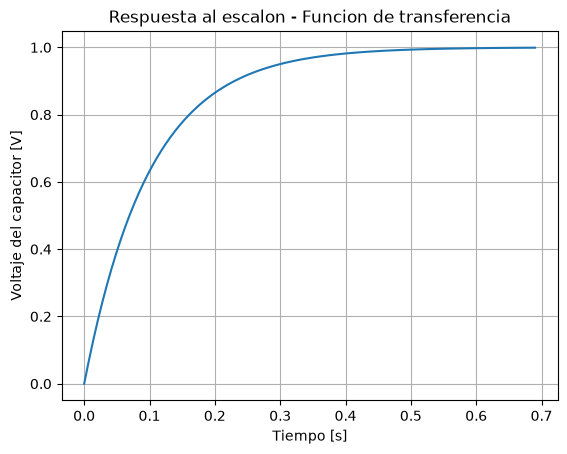

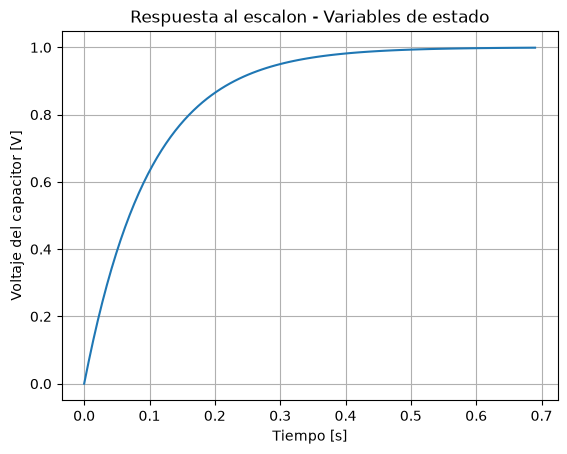

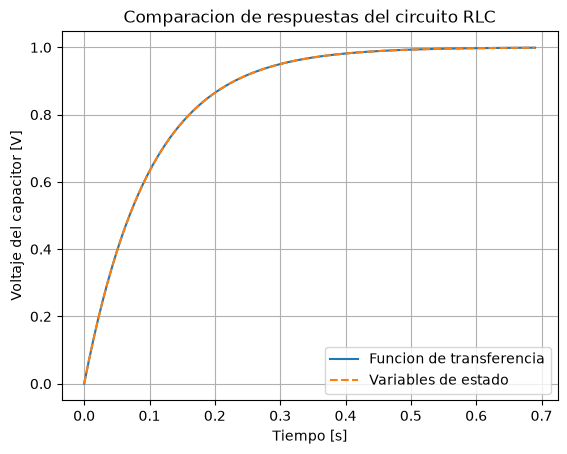

: 

In [ ]:
import control as ct
import matplotlib.pyplot as plt

# ============================================================
# MODELO DEL CIRCUITO RLC
# ============================================================

# Valores del circuito
R = 1000       # Resistencia [Ohm]
L = 0.1        # Inductancia [H]
C = 0.0001     # Capacitancia [F]

# ============================================================
# 1. FUNCION DE TRANSFERENCIA
# ============================================================

# G(s) = Vc(s) / E(s)
# G(s) = 1 / (LC*s^2 + RC*s + 1)

G = ct.tf(
    [1],
    [L*C, R*C, 1]
)

print("Funcion de transferencia:")
print(G)

# Respuesta al escalon
t1, y1 = ct.step_response(G)

plt.figure()
plt.plot(t1, y1)
plt.xlabel("Tiempo [s]")
plt.ylabel("Voltaje del capacitor [V]")
plt.title("Respuesta al escalon - Funcion de transferencia")
plt.grid()


# ============================================================
# 2. MODELO EN VARIABLES DE ESTADO
# ============================================================

A = [
    [-R/L, -1/L],
    [1/C, 0]
]

B = [
    [1/L],
    [0]
]

C_ss = [
    [0, 1]
]

D = [
    [0]
]

G_ss = ct.ss(A, B, C_ss, D)

# Respuesta al escalon
t2, y2 = ct.step_response(G_ss)

plt.figure()
plt.plot(t2, y2)
plt.xlabel("Tiempo [s]")
plt.ylabel("Voltaje del capacitor [V]")
plt.title("Respuesta al escalon - Variables de estado")
plt.grid()


# ============================================================
# 3. SUPERPOSICION DE LAS DOS RESPUESTAS
# ============================================================

plt.figure()

plt.plot(t1, y1, label="Funcion de transferencia")
plt.plot(t2, y2, "--", label="Variables de estado")

plt.xlabel("Tiempo [s]")
plt.ylabel("Voltaje del capacitor [V]")
plt.title("Comparacion de respuestas del circuito RLC")
plt.legend()
plt.grid()

plt.show()